# ДЗ 1
## Персонализированные рекомендации книг

Цель - разработать систему персонализированных рекомендаций для
книжного интернет-магазина, чтобы помочь покупателю выбрать подходящую литературу. При регистрации пользователь указывает краткую информацию о себе, например имя и возраст. На основе этих характеристик пользователя
и данных о предпочтениях других читателей система предлагает
книги, которые могут его заинтересовать.


### Датасет
Для выполнения этого исследования датасет брала с сайта Kaggle. Предоставлен датасет автором Alejandro Czernikier в виде трех таблиц: lectores.csv -информация о читателях; libros.csv -информация о книгах; entrenamiento.csv -взаимодействие читателей с книгами и бинарная метка предпочтения: 1 - книга понравилась, 0 -не понравилась.
Источник: https://www.kaggle.com/datasets/alejandroczernikier/books-dataset


### ML-постановка задачи

Бинарная классификация: на основе характеристик читателя
и книги предсказать, понравится ли ему эта книга.
Целевая переменная — `label`: 1 -понравилась, 0 -не понравилась.

In [ ]:
%pip install pandas matplotlib seaborn

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("raw_data/entrenamiento.csv")
readers = pd.read_csv("raw_data/lectores.csv")
books = pd.read_csv("raw_data/libros.csv")

display(train.head())
display(readers.head())
display(books.head())

In [14]:
train.shape, readers.shape, books.shape  # размеры таблиц

((41330, 3), (232, 5), (24414, 9))

In [ ]:
train.columns, readers.columns, books.columns

In [ ]:
train = train.rename(columns={   # для удобства в дальнейшей работе переименую столбцы на английский
    "id_lector": "reader_id",
    "id_libro": "book_id",
    "label": "liked"
})


display(train.head())

In [ ]:
 # для удобства в дальнейшей работе переименую столбцы на английский.
 # # в датасете с данными читателей тоже

readers = readers.rename(columns={  
    "id_lector": "reader_id",
    "nombre": "reader_name",
    "genero": "reader_gender",
    "vive_en": "reader_location",
    "nacimiento": "birth_year"
})

display(readers.head())

In [ ]:
books = books.rename(columns={
    "id_libro": "book_id",
    "titulo": "book_title",
    "author": "book_author",
    "genero": "book_genre",
    "editorial": "publisher",
    "anio_edicion": "edition_year",
    "isbn": "isbn",
    "resumen": "summary",
    "img_src": "image_url"
})

display(books.head())
    
    

### как результат шагов выше - переименовала название колонок в3х датасетах для более удобной работы далее.

### Далее делаю объединения таблиц

In [12]:
df = train.merge(readers, on="reader_id", how="left") # соединяю таблицы по колонке reader_id т к это колонка есть в обеих таблицах

In [15]:
df.columns # получилось 7 колонок, осталась одна reader_id.
# это хороший результат, так как до объединения у нас было в сумме в этих 2х датасетах 8 колонок, 
# # после объединения по айди читателя осталось 7


Index(['reader_id', 'book_id', 'liked', 'reader_name', 'reader_gender',
       'reader_location', 'birth_year'],
      dtype='str')

In [16]:
df_final = df.merge(books, on="book_id", how="left") #для получения большой таблицы присоединяю books и сливаю столбец book_id

In [17]:
display(df_final.columns) # финальная таблица содержит все колонки из всех 3х таблиц и НЕ повторяет столбцы
display(df_final.head())

Index(['reader_id', 'book_id', 'liked', 'reader_name', 'reader_gender',
       'reader_location', 'birth_year', 'book_title', 'autor', 'book_genre',
       'publisher', 'edition_year', 'isbn', 'summary', 'image_url'],
      dtype='str')

,reader_id,book_id,liked,reader_name,reader_gender,reader_location,birth_year,book_title,autor,book_genre,publisher,edition_year,isbn,summary,image_url
0,71,esperando-al-diluvio,0,eric,Hombre,Salamanca - España,1979.0,ESPERANDO AL DILUVIO,"REDONDO, DOLORES","Novela negra, intriga, terror",DESTINO,2022,9788423362479,"Entre los años 1968 y 1969, el asesino al que ...",https://quelibroleo.com/images/libros/libro-16...
1,92,el-topo-que-queria-saber-quien-se-habia-hecho-...,1,moses,Hombre,Vigo - España,1970.0,EL TOPO QUE QUERÍA SABER QUIÉN SE HABÍA HECHO ...,"HOLZWARTH, WERNER y ERLBUCH, WOLF",Infantil y juvenil,ALFAGUARA,2002,9788420443355,Un día el topo salió de su madriguera y le cay...,https://quelibroleo.com/images/libros/libro_12...
2,19,las-torres-de-sancho,1,angelines gómez lorenzo,Mujer,San sebastian - España,1958.0,LAS TORRES DE SANCHO,"MARTÍNEZ DE LEZEA, TOTI",Histórica y aventuras,MAEVA,2008,9788496231542,NaN,https://quelibroleo.com/images/libros/97884962...
3,216,el-problema-final,1,rodrigo,Hombre,Burgos - España,1981.0,EL PROBLEMA FINAL,"PEREZ REVERTE, ARTURO","Novela negra, intriga, terror",ALFAGUARA,2023,9788420476360,El nuevo libro del escritor y académico es una...,https://quelibroleo.com/images/libros/libro-16...
4,59,central-park,1,julio cassa huerta,Hombre,Vigo - España,1952.0,CENTRAL PARK,"MUSSO, GUILLAUME","Novela negra, intriga, terror",DEBOLSILLO,2015,9788490628119,NaN,https://quelibroleo.com/images/libros/libro_14...


In [19]:
df_final = df_final.sort_values(by="reader_id") #сортирую по айдишнику читателя
print(df_final.head()) 
print(df_final.info()) # 

       reader_id                                    book_id  liked  \
36426          1                                   protesis      1   
36608          1                    los-chicos-de-la-nickel      1   
18628          1                               bloody-miami      0   
27825          1  el-caso-saint-fiacre-los-casos-de-maigret      0   
602            1                                 las-madres      1   

         reader_name reader_gender  reader_location  birth_year  \
36426  antonio ocaña        Hombre  Madrid - España      1961.0   
36608  antonio ocaña        Hombre  Madrid - España      1961.0   
18628  antonio ocaña        Hombre  Madrid - España      1961.0   
27825  antonio ocaña        Hombre  Madrid - España      1961.0   
602    antonio ocaña        Hombre  Madrid - España      1961.0   

                                        book_title              autor  \
36426                                     PRÓTESIS     MARTÍN, ANDREU   
36608                      LOS

### Итого: 
пока что имеем такую структуру данных - 41 425 строк ( в нашем случае есть статистика по 41 425 взаимодействиям читатель-книга)
 и всего 15 столбцов, числовые признаки - float64(1), int64(2), текстовые столбцы(категориальные) - str(12)   
 0   reader_id        41425 non-null  int64  
 1   book_id          41425 non-null  object 
 2   liked            41425 non-null  int64  
 3   reader_name      41425 non-null  object 
 14  image_url        41425 non-null  object    - 5 признаков без пропусков, 

 также есть признаки с небольшим количеством пропуском. Но в целом, данные можно брать для анализа. 

 В признаке 11 edition_year тип данных - текстовый, но в таблице видно (после команды .head() ), что это числовой признак. 

In [20]:
df_final["edition_year"] = pd.to_numeric(df_final["edition_year"], errors="coerce")

df_final["edition_year"].dtype

dtype('float64')

In [21]:
df_final["edition_year"].isna().sum()

np.int64(245)

теперь признак edition_year числовой - float64. Количество пропуском - в разумных пределах, 245 строк пропущено.

### Мой главный интерес в анализе этого датасета - посмотреть, есть ли какие то более предпочитаемые жанры у разных поколений?

In [22]:
df_final["birth_year"].describe()

count    34009.000000
mean      1971.343733
std         14.961359
min       1910.000000
25%       1963.000000
50%       1975.000000
75%       1980.000000
max       2005.000000
Name: birth_year, dtype: float64

Видно, что отсчет поколений будет вестись с 1910 и по 2005. 
Следующим шагом разобью этот временной интервал на периоды.

In [ ]:
df_final["generation"] = pd.cut(
    df_final["birth_year"],
    bins=[1910, 1945, 1960, 1980, 2006],
    labels=["1910-1944", "1945-1959", "1960-1979", "1980-2005"],
    right=False
)

df_final["generation"].value_counts(dropna=False)

generation
1960-1979    16419
1980-2005    11315
NaN           7416
1945-1959     5569
1910-1944      706
Name: count, dtype: int64

Виден сильный перекос в поколении читателей. Большую часть выборки составляют люди 1960-1979 гг рождения. 1910-1944 самая малочисленная, этому может быть несколько причин: статистика начала вестись не так давно и многие из того поколения просто не дожили, либо если статистика ведется давно, то раннее поколение было малограмотным. 

В 7 416 строках не указан год рождения читателя. 
Но это было видно из команды .describe, когда было проанализировано count    34009.000000 образцов. 
К сожалению, их из анализа придется исключить.

In [24]:
df_gen = df_final.dropna(subset=["generation"]) # удаляем те строки, в которых в столбце generation нет значения. 
# Также делаем новую таблицу df_gen, старая df_final  останется неизменной

In [25]:
liked_books = df_gen[df_gen["liked"] == 1] # создаем новую таблицу, куда войдут только те строчки, 
# в которых книга "понравилась"

pd.crosstab(liked_books["generation"], liked_books["book_genre"]) # делаем сводную таблицу частота жанра\поколение

book_genre,Actores,Administración y dirección empresarial,Arte,Autoayuda,Autoayuda Y Espiritualidad,"Biografiás, Memorias","Biografías, Memorias",Ciencias,Ciencias Humanas,Ciencias Políticas Y Sociales,...,No Ficción,No ficción,Novela negra,"Novela negra, intriga, terror",Poesía,"Poesía, Teatro","Poesía, teatro","Romántica, erótica",Varios,varios
generation,,,,,,,,,,,,,,,,,,,,,
1910-1944,0,0,0,0,0,0,11,0,0,0,...,4,1,0,51,0,1,2,9,5,0
1945-1959,2,0,2,0,1,0,80,0,0,0,...,27,2,1,1570,0,0,19,87,11,1
1960-1979,2,1,4,0,9,0,276,1,4,6,...,87,10,0,2528,1,2,102,317,47,0
1980-2005,1,0,4,1,12,1,181,1,1,0,...,81,10,1,1454,0,6,112,147,36,0


In [26]:
genre_by_gen = pd.crosstab(    # считаем в долях
    liked_books["generation"],
    liked_books["book_genre"],
    normalize="index"
) * 100

genre_by_gen.round(2) 

book_genre,Actores,Administración y dirección empresarial,Arte,Autoayuda,Autoayuda Y Espiritualidad,"Biografiás, Memorias","Biografías, Memorias",Ciencias,Ciencias Humanas,Ciencias Políticas Y Sociales,...,No Ficción,No ficción,Novela negra,"Novela negra, intriga, terror",Poesía,"Poesía, Teatro","Poesía, teatro","Romántica, erótica",Varios,varios
generation,,,,,,,,,,,,,,,,,,,,,
1910-1944,0.00,0.00,0.00,0.00,0.00,0.00,2.21,0.00,0.00,0.00,...,0.80,0.20,0.00,10.26,0.00,0.20,0.40,1.81,1.01,0.00
1945-1959,0.05,0.00,0.05,0.00,0.03,0.00,2.18,0.00,0.00,0.00,...,0.74,0.05,0.03,42.85,0.00,0.00,0.52,2.37,0.30,0.03
1960-1979,0.02,0.01,0.04,0.00,0.08,0.00,2.45,0.01,0.04,0.05,...,0.77,0.09,0.00,22.42,0.01,0.02,0.90,2.81,0.42,0.00
1980-2005,0.01,0.00,0.06,0.01,0.17,0.01,2.49,0.01,0.01,0.00,...,1.11,0.14,0.01,20.00,0.00,0.08,1.54,2.02,0.50,0.00


In [27]:
top_genres = liked_books["book_genre"].value_counts().head(6).index # сколько раз встречается каждый женр и берем топ-6


liked_top = liked_books[liked_books["book_genre"].isin(top_genres)] # убираем все жанры не из топ-6

In [28]:
genre_by_gen_top = pd.crosstab(
    liked_top["generation"],
    liked_top["book_genre"],
    normalize="index"
) * 100

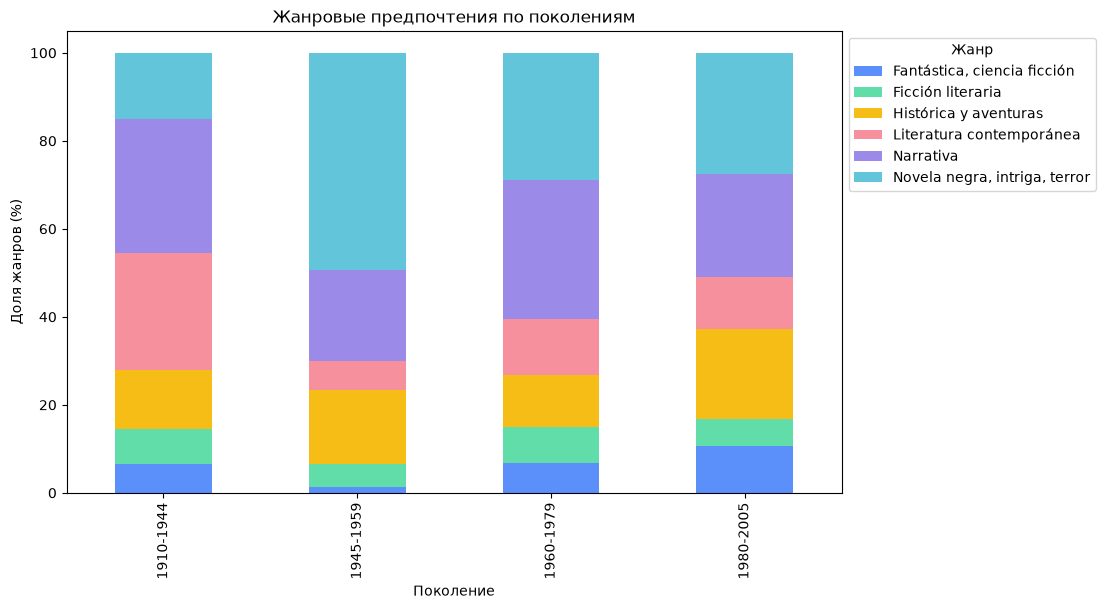

In [30]:
import matplotlib.pyplot as plt


genre_by_gen_top.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["#5B8FF9", "#61DDAA", "#F6BD16",
           "#F6909D", "#9B8AE8", "#63C5DA"]
)

plt.title("Жанровые предпочтения по поколениям")
plt.xlabel("Поколение")
plt.ylabel("Доля жанров (%)")
plt.legend(title="Жанр", bbox_to_anchor=(1, 1))
plt.show()

In [31]:
genre_translation_en = {
    "Fantástica, ciencia ficción": "Fantasy & Sci-Fi",
    "Ficción literaria": "Literary Fiction",
    "Histórica y aventuras": "Historical & Adventure",
    "Literatura contemporánea": "Contemporary Literature",
    "Narrativa": "Prose",
    "Novela negra, intriga, terror": "Crime / Thriller / Horror"
}

In [32]:
liked_top = liked_top.copy()

liked_top["book_genre_en"] = liked_top["book_genre"].map(genre_translation_en)

In [33]:
genre_by_gen_top = pd.crosstab(
    liked_top["generation"],
    liked_top["book_genre_en"],
    normalize="index"
) * 100

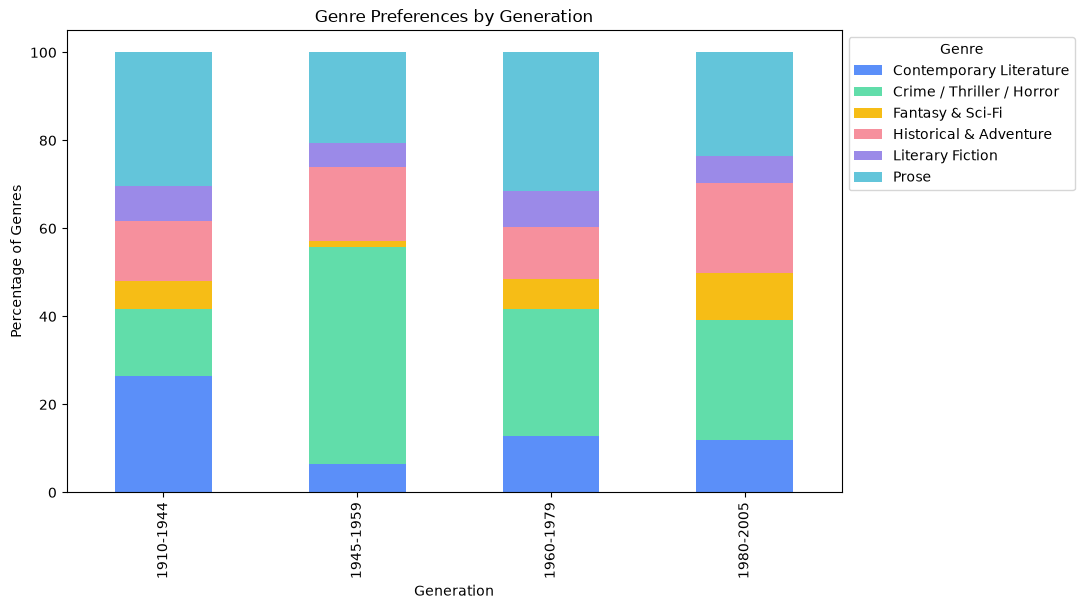

In [35]:
import matplotlib.pyplot as plt

genre_by_gen_top.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["#5B8FF9", "#61DDAA", "#F6BD16",
           "#F6909D", "#9B8AE8", "#63C5DA"]
)

plt.title("Genre Preferences by Generation")
plt.xlabel("Generation")
plt.ylabel("Percentage of Genres")
plt.legend(title="Genre", bbox_to_anchor=(1, 1))
plt.show()





### Промежуточный вывод:

более молодое поколение (1980-2005) чаще предпочитает фантастику и художественную литературу.

У более старших поколений (1945-1959 и 1960-1979) выше доля детективов, триллеров и прозы.

Исторической и приключенческой литературой увлекаются все поколения примерно одинаково.


### Корреляции числовых переменных

Рассмотрю связь года рождения читателя, года издания книги и оценки "liked"

              birth_year  edition_year     liked
birth_year      1.000000      0.016769 -0.011412
edition_year    0.016769      1.000000  0.072624
liked          -0.011412      0.072624  1.000000


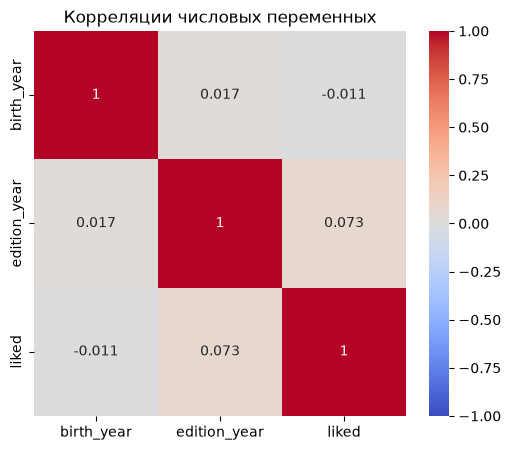

In [36]:
correlation_data = df_final[["birth_year", "edition_year", "liked"]].dropna()

pearson_correlation = correlation_data.corr(method="pearson")
print(pearson_correlation)

plt.figure(figsize=(6, 5))
sns.heatmap(
    pearson_correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Корреляции числовых переменных")
plt.show()

### Промежуточные выводы
Видно, что корреляции года рождения и года издания с оценкой книги близки к нулю. То есть явной линейной связи здесь нет

### Распределение года рождения читателей

Рассмотрю распределение годов рождения и возможные выбросы.
Использую таблицу `readers`, чтобы учитывать каждого читателя
один раз.

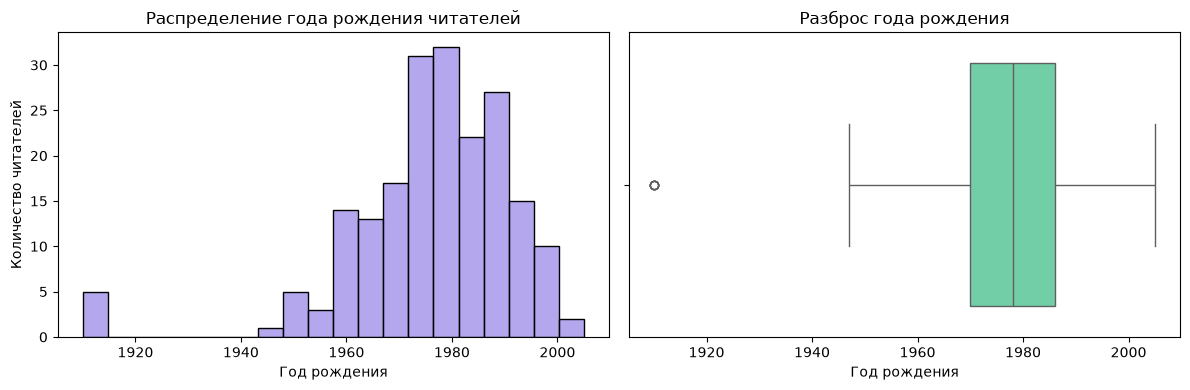

In [37]:
birth_year_data = readers["birth_year"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    birth_year_data,
    bins=20,
    color="#9B8AE8",
    ax=axes[0]
)
axes[0].set_title("Распределение года рождения читателей")
axes[0].set_xlabel("Год рождения")
axes[0].set_ylabel("Количество читателей")

sns.boxplot(
    x=birth_year_data,
    color="#61DDAA",
    ax=axes[1]
)
axes[1].set_title("Разброс года рождения")
axes[1].set_xlabel("Год рождения")

plt.tight_layout()
plt.show()

### промежуточный вывод
Большая часть читателей родилась примерно в 1960-1990 годах.
Читателей с более ранними года
ми рождения заметно меньше.

напоминаю (себе), зачем все это делается

### ML-постановка задачи
Бинарная классификация: на основе характеристик читателя
и книги предсказать, понравится ли ему эта книга.
Целевая переменная -"label" : 1 -понравилась, 0 -не понравилась.

### Метрика качества

Основная метрика - precision для класса 1 (`"книга понравилась"`). Она показывает, какая доля книг, которые модель считает
подходящими, действительно понравилась читателям. Для нашей задачи важно, чтобы среди предложенных книг было меньше
неподходящих рекомендаций.

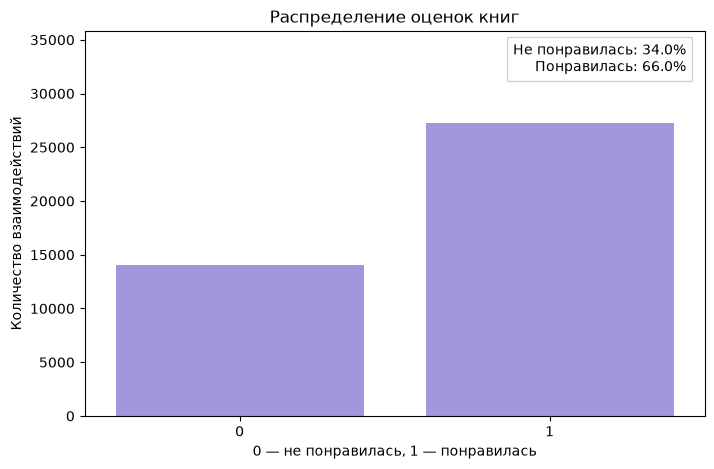

In [ ]:
p = train["liked"].value_counts(normalize=True) * 100

plt.figure(figsize=(8, 5))
sns.countplot(data=train, x="liked", order=[0, 1], color="#9B8AE8")

plt.title("Распределение оценок книг")
plt.xlabel("0 - не понравилась, 1 -понравилась")
plt.ylabel("Количество взаимодействий")

plt.text(
    0.97, 0.97,
    f"Не понравилась: {p.get(0, 0):.1f}%\nПонравилась: {p.get(1, 0):.1f}%",
    transform=plt.gca().transAxes,
    ha="right", va="top",
    bbox=dict(facecolor="white", edgecolor="lightgray")
)

plt.ylim(0, plt.ylim()[1] * 1.25)
plt.show()

### Вывод:
-Положительные оценки встречаются чаще отрицательных;
-Классы `(понравилось vs не понравилось)` представлены неравномерно;
-Метрика precision покажет, какая доля рекомендованных моделью книг действительно понравилась читателям.